In [1]:
import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"

print("Legacy Keras enabled:", os.environ["TF_USE_LEGACY_KERAS"])

Legacy Keras enabled: 1


In [2]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


In [3]:
import tensorflow_recommenders as tfrs

print("TFRS imported successfully")

TFRS imported successfully


In [4]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current working directory:
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\notebooks

Files/folders here:
['.gitkeep', '.ipynb_checkpoints', '01_data_exploration.ipynb', '02_two_tower_training.ipynb']


In [5]:
import os

project_root = os.path.dirname(os.getcwd())
processed_path = os.path.join(project_root, "data", "processed")

print("Processed data path:")
print(processed_path)

print("\nFiles found:")
print(os.listdir(processed_path) if os.path.exists(processed_path) else "FOLDER DOES NOT EXIST")

Processed data path:
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\data\processed

Files found:
['.gitkeep', 'eda', 'enriched_item_features.csv', 'enriched_user_features.csv', 'item_features.csv', 'train_interactions.csv', 'user_features.csv', 'validation_interactions.csv']


In [8]:
import pandas as pd

train_df = pd.read_csv(
    "../data/processed/train_interactions.csv"
)

validation_df = pd.read_csv(
    "../data/processed/validation_interactions.csv"
)

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)

display(train_df.head())

Training shape: (2002124, 5)
Validation shape: (300304, 5)


,customer_id,article_id,t_dat,price,sales_channel_id
0,1df66db5879e417a7fc536e7002a100ec1a4c673afa290...,613459001,2018-09-20,0.008458,1
1,5250bcfee00a4450fdadc7cdf2f59c16e133f8f5150ca3...,396135007,2018-09-20,0.016932,2
2,5efd9c51957f67ecebae80fdca8c798a71433dbd11f347...,597082002,2018-09-20,0.020322,2
3,66741874480ea977cde0e1ffc1af60bbbf1d3441b311f4...,615141003,2018-09-20,0.025407,2
4,6d9b1191c4740f19314cca9889c641d0fd06d2ac621485...,690992001,2018-09-20,0.016932,2


In [9]:
print("=== TRAINING DATA ===")
print("Unique users:", train_df["customer_id"].nunique())
print("Unique items:", train_df["article_id"].nunique())

print("\n=== VALIDATION DATA ===")
print("Unique users:", validation_df["customer_id"].nunique())
print("Unique items:", validation_df["article_id"].nunique())

print("\n=== DATA TYPES ===")
print(train_df.dtypes)

print("\n=== MISSING VALUES ===")
print(train_df.isna().sum())
print(validation_df.isna().sum())

=== TRAINING DATA ===
Unique users: 687245
Unique items: 79407

=== VALIDATION DATA ===
Unique users: 153790
Unique items: 21496

=== DATA TYPES ===
customer_id             str
article_id            int64
t_dat                   str
price               float64
sales_channel_id      int64
dtype: object

=== MISSING VALUES ===
customer_id         0
article_id          0
t_dat               0
price               0
sales_channel_id    0
dtype: int64
customer_id         0
article_id          0
t_dat               0
price               0
sales_channel_id    0
dtype: int64


In [10]:
import numpy as np

# Training vocabularies
user_ids = train_df["customer_id"].astype(str).unique()
item_ids = train_df["article_id"].astype(str).unique()

print("User vocabulary size:", len(user_ids))
print("Item vocabulary size:", len(item_ids))

print("\nSample user IDs:")
print(user_ids[:5])

print("\nSample item IDs:")
print(item_ids[:5])

User vocabulary size: 687245
Item vocabulary size: 79407

Sample user IDs:
<StringArray>
['1df66db5879e417a7fc536e7002a100ec1a4c673afa290b9dcaf56e6d28473a0',
 '5250bcfee00a4450fdadc7cdf2f59c16e133f8f5150ca37e1bad1fff6d03fe41',
 '5efd9c51957f67ecebae80fdca8c798a71433dbd11f34754f587ec1cd0c4e729',
 '66741874480ea977cde0e1ffc1af60bbbf1d3441b311f47d394c60690e258795',
 '6d9b1191c4740f19314cca9889c641d0fd06d2ac62148578795e8b4587600116']
Length: 5, dtype: str

Sample item IDs:
<StringArray>
['613459001', '396135007', '597082002', '615141003', '690992001']
Length: 5, dtype: str


In [11]:
import tensorflow as tf

# Keep only the fields needed for the first Two-Tower retrieval model
train_data = train_df[["customer_id", "article_id"]].copy()
validation_data = validation_df[["customer_id", "article_id"]].copy()

# TensorFlow expects consistent string IDs
train_data["customer_id"] = train_data["customer_id"].astype(str)
train_data["article_id"] = train_data["article_id"].astype(str)

validation_data["customer_id"] = validation_data["customer_id"].astype(str)
validation_data["article_id"] = validation_data["article_id"].astype(str)

# Convert pandas dataframes to TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices({
    "customer_id": train_data["customer_id"].values,
    "article_id": train_data["article_id"].values,
})

validation_ds = tf.data.Dataset.from_tensor_slices({
    "customer_id": validation_data["customer_id"].values,
    "article_id": validation_data["article_id"].values,
})

print("Training dataset:", train_ds)
print("Validation dataset:", validation_ds)

Training dataset: <_TensorSliceDataset element_spec={'customer_id': TensorSpec(shape=(), dtype=tf.string, name=None), 'article_id': TensorSpec(shape=(), dtype=tf.string, name=None)}>
Validation dataset: <_TensorSliceDataset element_spec={'customer_id': TensorSpec(shape=(), dtype=tf.string, name=None), 'article_id': TensorSpec(shape=(), dtype=tf.string, name=None)}>


In [12]:
BATCH_SIZE = 8192

train_ds = train_ds.shuffle(
    buffer_size=len(train_data),
    seed=42,
    reshuffle_each_iteration=True
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

validation_ds = validation_ds.batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

print("Batch size:", BATCH_SIZE)
print("Training dataset ready.")
print("Validation dataset ready.")

Batch size: 8192
Training dataset ready.
Validation dataset ready.


In [13]:
# Final vocabulary lists for TensorFlow lookup layers

user_vocabulary = user_ids.tolist()
item_vocabulary = item_ids.tolist()

print("User vocabulary size:", len(user_vocabulary))
print("Item vocabulary size:", len(item_vocabulary))

User vocabulary size: 687245
Item vocabulary size: 79407


In [14]:
# ==============================
# USER TOWER
# ==============================

embedding_dimension = 64

user_model = tf.keras.Sequential([
    tf.keras.layers.StringLookup(
        vocabulary=user_vocabulary,
        mask_token=None
    ),
    tf.keras.layers.Embedding(
        input_dim=len(user_vocabulary) + 1,
        output_dim=embedding_dimension
    )
])

print("User tower created successfully.")
print("Embedding dimension:", embedding_dimension)


User tower created successfully.
Embedding dimension: 64


In [15]:
# ==============================
# ITEM TOWER
# ==============================

item_model = tf.keras.Sequential([
    tf.keras.layers.StringLookup(
        vocabulary=item_vocabulary,
        mask_token=None
    ),
    tf.keras.layers.Embedding(
        input_dim=len(item_vocabulary) + 1,
        output_dim=embedding_dimension
    )
])

print("Item tower created successfully.")
print("Embedding dimension:", embedding_dimension)

Item tower created successfully.
Embedding dimension: 64


In [19]:
# ==============================
# ITEM CANDIDATE DATASET
# ==============================

item_ds = tf.data.Dataset.from_tensor_slices(
    item_vocabulary
)

item_ds = item_ds.batch(128).prefetch(tf.data.AUTOTUNE)

print("Item candidate dataset created.")
print("Candidate items:", len(item_vocabulary))

Item candidate dataset created.
Candidate items: 79407


In [24]:
# ==============================
# TWO-TOWER RETRIEVAL MODEL
# ==============================

class TwoTowerModel(tfrs.Model):

    def __init__(self, user_model, item_model):
        super().__init__()

        self.user_model = user_model
        self.item_model = item_model

        # Candidate dataset must contain article IDs as strings.
        candidate_dataset = (
            tf.data.Dataset.from_tensor_slices(item_vocabulary)
            .batch(128)
            .map(
                lambda article_id: self.item_model(article_id),
                num_parallel_calls=tf.data.AUTOTUNE
            )
            .prefetch(tf.data.AUTOTUNE)
        )

        self.task = tfrs.tasks.Retrieval(
            metrics=tfrs.metrics.FactorizedTopK(
                candidates=candidate_dataset
            )
        )

    def compute_loss(self, features, training=False):
        user_embeddings = self.user_model(features["customer_id"])
        item_embeddings = self.item_model(features["article_id"])

        return self.task(
            user_embeddings,
            item_embeddings,
            compute_metrics=not training
        )


two_tower_model = TwoTowerModel(
    user_model,
    item_model
)

print("Two-Tower model recreated successfully.")

Two-Tower model recreated successfully.


In [25]:
# ==============================
# COMPILE TWO-TOWER MODEL
# ==============================
two_tower_model.compile(
    optimizer=tf.keras.optimizers.Adagrad(learning_rate=0.1)
)

print("Two-Tower model compiled successfully.")

Two-Tower model compiled successfully.


In [22]:
# ==============================
# TRAINING SMOKE TEST
# ==============================

history = two_tower_model.fit(
    train_ds.take(100),
    epochs=1
)

print("Smoke test training completed.")

100/100 [==============================] - 115s 981ms/step - factorized_top_k/top_1_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_5_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_10_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_50_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_100_categorical_accuracy: 0.0000e+00 - loss: 73817.3431 - regularization_loss: 0.0000e+00 - total_loss: 73817.3431
Smoke test training completed.


In [26]:
test_result = two_tower_model.evaluate(
    validation_ds.take(1),
    return_dict=True
)

print(test_result)

1/1 [==============================] - 12s 12s/step - factorized_top_k/top_1_categorical_accuracy: 8.5449e-04 - factorized_top_k/top_5_categorical_accuracy: 0.0038 - factorized_top_k/top_10_categorical_accuracy: 0.0052 - factorized_top_k/top_50_categorical_accuracy: 0.0122 - factorized_top_k/top_100_categorical_accuracy: 0.0168 - loss: 73867.2031 - regularization_loss: 0.0000e+00 - total_loss: 73867.2031
{'factorized_top_k/top_1_categorical_accuracy': 0.0008544921875, 'factorized_top_k/top_5_categorical_accuracy': 0.0037841796875, 'factorized_top_k/top_10_categorical_accuracy': 0.0052490234375, 'factorized_top_k/top_50_categorical_accuracy': 0.01220703125, 'factorized_top_k/top_100_categorical_accuracy': 0.016845703125, 'loss': 73867.203125, 'regularization_loss': 0.0, 'total_loss': 73867.203125}


In [27]:
# ==============================
# BASELINE TWO-TOWER TRAINING
# ==============================

history = two_tower_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=3
)

print("Baseline Two-Tower training completed.")

Epoch 1/3
245/245 [==============================] - 595s 2s/step - factorized_top_k/top_1_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_5_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_10_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_50_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_100_categorical_accuracy: 0.0000e+00 - loss: 65085.7959 - regularization_loss: 0.0000e+00 - total_loss: 65085.7959 - val_factorized_top_k/top_1_categorical_accuracy: 4.4288e-04 - val_factorized_top_k/top_5_categorical_accuracy: 0.0015 - val_factorized_top_k/top_10_categorical_accuracy: 0.0019 - val_factorized_top_k/top_50_categorical_accuracy: 0.0047 - val_factorized_top_k/top_100_categorical_accuracy: 0.0076 - val_loss: 47220.0703 - val_regularization_loss: 0.0000e+00 - val_total_loss: 47220.0703
Epoch 2/3
245/245 [==============================] - 597s 2s/step - factorized_top_k/top_1_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_5_categorical_accuracy: 0.0

In [28]:
# ==============================
# BASELINE METRIC SUMMARY
# ==============================

print("Baseline Two-Tower Results")
print("=" * 40)

for epoch in range(3):
    print(f"\nEpoch {epoch + 1}")
    print(
        "Val Top-1:  ",
        history.history["val_factorized_top_k/top_1_categorical_accuracy"][epoch]
    )
    print(
        "Val Top-5:  ",
        history.history["val_factorized_top_k/top_5_categorical_accuracy"][epoch]
    )
    print(
        "Val Top-10: ",
        history.history["val_factorized_top_k/top_10_categorical_accuracy"][epoch]
    )
    print(
        "Val Top-50: ",
        history.history["val_factorized_top_k/top_50_categorical_accuracy"][epoch]
    )
    print(
        "Val Top-100:",
        history.history["val_factorized_top_k/top_100_categorical_accuracy"][epoch]
    )
    print(
        "Val Loss:   ",
        history.history["val_loss"][epoch]
    ) 

Baseline Two-Tower Results

Epoch 1
Val Top-1:   0.0004428845422808081
Val Top-5:   0.0015384410507977009
Val Top-10:  0.0019080664496868849
Val Top-50:  0.0047218818217515945
Val Top-100: 0.0075756567530334
Val Loss:    47220.0703125

Epoch 2
Val Top-1:   0.0004262347356416285
Val Top-5:   0.0014918216038495302
Val Top-10:  0.001801507780328393
Val Top-50:  0.003416538005694747
Val Top-100: 0.00540785351768136
Val Loss:    48866.18359375

Epoch 3
Val Top-1:   0.0003662954841274768
Val Top-5:   0.0013686130987480283
Val Top-10:  0.0017781980568543077
Val Top-50:  0.003040252486243844
Val Top-100: 0.004621983040124178
Val Loss:    50487.8515625


In [29]:
# ==============================
# INSPECT ENGINEERED FEATURES
# ==============================

user_features_path = os.path.join(
    processed_path,
    "enriched_user_features.csv"
)

item_features_path = os.path.join(
    processed_path,
    "enriched_item_features.csv"
)

user_features_df = pd.read_csv(user_features_path)
item_features_df = pd.read_csv(item_features_path)

print("User features shape:", user_features_df.shape)
print("Item features shape:", item_features_df.shape)

print("\nUser feature columns:")
print(user_features_df.columns.tolist())

print("\nItem feature columns:")
print(item_features_df.columns.tolist())

User features shape: (1371980, 11)
Item features shape: (105542, 20)

User feature columns:
['customer_id', 'FN', 'Active', 'club_member_status', 'fashion_news_frequency', 'age', 'purchase_count', 'avg_purchase_price', 'total_spend', 'first_purchase_date', 'last_purchase_date']

Item feature columns:
['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_name', 'colour_group_name', 'perceived_colour_value_name', 'perceived_colour_master_name', 'department_name', 'index_name', 'index_group_name', 'section_name', 'garment_group_name', 'purchase_count', 'avg_price', 'total_revenue', 'first_purchase_date', 'last_purchase_date']


In [30]:
# ==============================
# PREPARE CONTEXT FEATURES
# ==============================

user_numeric_features = [
    "age",
    "purchase_count",
    "avg_purchase_price",
    "total_spend"
]

item_numeric_features = [
    "product_type_no",
    "purchase_count",
    "avg_price",
    "total_revenue"
]

print("User numeric features:")
print(user_numeric_features)

print("\nItem numeric features:")
print(item_numeric_features)

User numeric features:
['age', 'purchase_count', 'avg_purchase_price', 'total_spend']

Item numeric features:
['product_type_no', 'purchase_count', 'avg_price', 'total_revenue']


In [31]:
# ==============================
# NORMALIZE CONTEXT FEATURES
# ==============================

from sklearn.preprocessing import StandardScaler

user_scaler = StandardScaler()
item_scaler = StandardScaler()

user_features_df[user_numeric_features] = user_scaler.fit_transform(
    user_features_df[user_numeric_features].fillna(0)
)

item_features_df[item_numeric_features] = item_scaler.fit_transform(
    item_features_df[item_numeric_features].fillna(0)
)

print("User numeric features normalized.")
print("Item numeric features normalized.")

print("\nUser feature sample:")
print(user_features_df[user_numeric_features].head())

print("\nItem feature sample:")
print(item_features_df[item_numeric_features].head())

User numeric features normalized.
Item numeric features normalized.

User feature sample:
        age  purchase_count  avg_purchase_price  total_spend
0  1.086835       -0.259748            0.524670    -0.146579
1  1.357972        3.545921            0.163341     3.652145
2  2.645876       -0.540703            0.075637    -0.490136
3  0.341206       -0.412996           -0.586301    -0.422089
4 -0.336638        0.353246            0.289694     0.474177

Item feature sample:
   product_type_no  purchase_count  avg_price  total_revenue
0         0.241684       13.374177  -0.786964       3.680006
1         0.241684        8.817484  -0.788032       2.323897
2         0.241684       -0.109370  -0.909251      -0.336821
3         0.947890        0.942565  -0.319856       0.586307
4         0.947890        0.301760  -0.397735       0.065916


In [33]:
print("Context training columns:")
print(context_train_df.columns.tolist())



Context training columns:
['customer_id', 'article_id', 't_dat', 'price', 'sales_channel_id', 'age', 'purchase_count_x', 'avg_purchase_price', 'total_spend', 'product_type_no', 'purchase_count_y', 'avg_price', 'total_revenue']


In [34]:
# Rename merged purchase-count columns
context_train_df = context_train_df.rename(
    columns={
        "purchase_count_x": "user_purchase_count",
        "purchase_count_y": "item_purchase_count"
    }
)

print("Context-aware training columns:")
print(context_train_df.columns.tolist())

print("\nMissing values:")
print(
    context_train_df[
        [
            "age",
            "user_purchase_count",
            "avg_purchase_price",
            "total_spend",
            "product_type_no",
            "item_purchase_count",
            "avg_price",
            "total_revenue"
        ]
    ].isna().sum()
)

Context-aware training columns:
['customer_id', 'article_id', 't_dat', 'price', 'sales_channel_id', 'age', 'user_purchase_count', 'avg_purchase_price', 'total_spend', 'product_type_no', 'item_purchase_count', 'avg_price', 'total_revenue']

Missing values:
age                    0
user_purchase_count    0
avg_purchase_price     0
total_spend            0
product_type_no        0
item_purchase_count    0
avg_price              0
total_revenue          0
dtype: int64


In [35]:
context_features = [
    "age",
    "user_purchase_count",
    "avg_purchase_price",
    "total_spend",
    "product_type_no",
    "item_purchase_count",
    "avg_price",
    "total_revenue"
]

context_train_ds = tf.data.Dataset.from_tensor_slices({
    "customer_id": context_train_df["customer_id"].astype(str).values,
    "article_id": context_train_df["article_id"].astype(str).values,
    "age": context_train_df["age"].astype("float32").values,
    "user_purchase_count": context_train_df["user_purchase_count"].astype("float32").values,
    "avg_purchase_price": context_train_df["avg_purchase_price"].astype("float32").values,
    "total_spend": context_train_df["total_spend"].astype("float32").values,
    "product_type_no": context_train_df["product_type_no"].astype("float32").values,
    "item_purchase_count": context_train_df["item_purchase_count"].astype("float32").values,
    "avg_price": context_train_df["avg_price"].astype("float32").values,
    "total_revenue": context_train_df["total_revenue"].astype("float32").values
})

context_train_ds = (
    context_train_ds
    .shuffle(100_000, seed=42)
    .batch(8192)
    .prefetch(tf.data.AUTOTUNE)
)

print("Context-aware TensorFlow dataset created.")

Context-aware TensorFlow dataset created.


In [36]:
context_batch = next(iter(context_train_ds))

print("Batch keys:")
print(context_batch.keys())

print("\nCustomer ID shape:", context_batch["customer_id"].shape)
print("Article ID shape:", context_batch["article_id"].shape)
print("Age shape:", context_batch["age"].shape)
print("Total spend shape:", context_batch["total_spend"].shape)

Batch keys:
dict_keys(['customer_id', 'article_id', 'age', 'user_purchase_count', 'avg_purchase_price', 'total_spend', 'product_type_no', 'item_purchase_count', 'avg_price', 'total_revenue'])

Customer ID shape: (8192,)
Article ID shape: (8192,)
Age shape: (8192,)
Total spend shape: (8192,)


In [37]:
class ContextUserTower(tf.keras.Model):

    def __init__(self, user_vocabulary, embedding_dimension=64):
        super().__init__()

        self.user_lookup = tf.keras.layers.StringLookup(
            vocabulary=user_vocabulary,
            mask_token=None
        )

        self.user_embedding = tf.keras.layers.Embedding(
            input_dim=len(user_vocabulary) + 1,
            output_dim=embedding_dimension
        )

        self.context_projection = tf.keras.Sequential([
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(embedding_dimension)
        ])

        self.normalization = tf.keras.layers.LayerNormalization()

    def call(self, inputs):
        user_ids = inputs["customer_id"]

        user_indices = self.user_lookup(user_ids)
        user_embedding = self.user_embedding(user_indices)

        context = tf.stack([
            inputs["age"],
            inputs["user_purchase_count"],
            inputs["avg_purchase_price"],
            inputs["total_spend"]
        ], axis=1)

        context_embedding = self.context_projection(context)

        combined = user_embedding + context_embedding

        return self.normalization(combined)


context_user_model = ContextUserTower(
    user_vocabulary=user_vocabulary,
    embedding_dimension=64
)

print("Context-aware User Tower created.")

Context-aware User Tower created.


In [38]:
user_context_embeddings = context_user_model(context_batch)

print("User embedding shape:", user_context_embeddings.shape)


User embedding shape: (8192, 64)


In [39]:
class ContextItemTower(tf.keras.Model):

    def __init__(self, item_vocabulary, embedding_dimension=64):
        super().__init__()

        self.item_lookup = tf.keras.layers.StringLookup(
            vocabulary=item_vocabulary,
            mask_token=None
        )

        self.item_embedding = tf.keras.layers.Embedding(
            input_dim=len(item_vocabulary) + 1,
            output_dim=embedding_dimension
        )

        self.context_projection = tf.keras.Sequential([
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(embedding_dimension)
        ])

        self.normalization = tf.keras.layers.LayerNormalization()

    def call(self, inputs):
        item_ids = inputs["article_id"]

        item_indices = self.item_lookup(item_ids)
        item_embedding = self.item_embedding(item_indices)

        context = tf.stack([
            inputs["product_type_no"],
            inputs["item_purchase_count"],
            inputs["avg_price"],
            inputs["total_revenue"]
        ], axis=1)

        context_embedding = self.context_projection(context)

        combined = item_embedding + context_embedding

        return self.normalization(combined)


context_item_model = ContextItemTower(
    item_vocabulary=item_vocabulary,
    embedding_dimension=64
)

print("Context-aware Item Tower created.")

Context-aware Item Tower created.


In [40]:
item_context_embeddings = context_item_model(context_batch)

print("Item embedding shape:", item_context_embeddings.shape)

Item embedding shape: (8192, 64)


In [41]:
class ContextAwareTwoTowerModel(tfrs.Model):

    def __init__(
        self,
        user_model,
        item_model,
        item_vocabulary
    ):
        super().__init__()

        self.user_model = user_model
        self.item_model = item_model

        candidate_dataset = (
            tf.data.Dataset.from_tensor_slices(item_vocabulary)
            .batch(128)
            .map(
                lambda article_id: self.item_model({
                    "article_id": article_id,
                    "product_type_no": tf.zeros(
                        tf.shape(article_id),
                        dtype=tf.float32
                    ),
                    "item_purchase_count": tf.zeros(
                        tf.shape(article_id),
                        dtype=tf.float32
                    ),
                    "avg_price": tf.zeros(
                        tf.shape(article_id),
                        dtype=tf.float32
                    ),
                    "total_revenue": tf.zeros(
                        tf.shape(article_id),
                        dtype=tf.float32
                    )
                }),
                num_parallel_calls=tf.data.AUTOTUNE
            )
            .prefetch(tf.data.AUTOTUNE)
        )

        self.task = tfrs.tasks.Retrieval(
            metrics=tfrs.metrics.FactorizedTopK(
                candidates=candidate_dataset
            )
        )

    def compute_loss(self, features, training=False):

        user_embeddings = self.user_model(features)

        item_embeddings = self.item_model(features)

        return self.task(
            user_embeddings,
            item_embeddings,
            compute_metrics=not training
        )


context_two_tower_model = ContextAwareTwoTowerModel(
    user_model=context_user_model,
    item_model=context_item_model,
    item_vocabulary=item_vocabulary
)

context_two_tower_model.compile(
    optimizer=tf.keras.optimizers.Adagrad(
        learning_rate=0.1
    )
)

print("Context-aware Two-Tower model created.")

Context-aware Two-Tower model created.


In [42]:
smoke_batch = next(iter(context_train_ds))

smoke_loss = context_two_tower_model.compute_loss(
    smoke_batch,
    training=True
)

print("Smoke-test loss:", float(smoke_loss))

Smoke-test loss: 126373.234375


In [43]:
context_history = context_two_tower_model.fit(
    context_train_ds,
    epochs=3
)

print("Context-aware training completed.")

Epoch 1/3
245/245 [==============================] - 1018s 4s/step - factorized_top_k/top_1_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_5_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_10_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_50_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_100_categorical_accuracy: 0.0000e+00 - loss: 75710.4247 - regularization_loss: 0.0000e+00 - total_loss: 75710.4247
Epoch 2/3
245/245 [==============================] - 787s 3s/step - factorized_top_k/top_1_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_5_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_10_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_50_categorical_accuracy: 0.0000e+00 - factorized_top_k/top_100_categorical_accuracy: 0.0000e+00 - loss: 69796.9336 - regularization_loss: 0.0000e+00 - total_loss: 69796.9336
Epoch 3/3
245/245 [==============================] - 403s 2s/step - factorized_top_k/top_1_categorical_accuracy: 0.0000e+00

In [45]:
context_validation_df = context_validation_df.rename(
    columns={
        "purchase_count_x": "user_purchase_count",
        "purchase_count_y": "item_purchase_count"
    }
)

print("Context-aware validation columns:")
print(context_validation_df.columns.tolist())

print("\nMissing values:")
print(
    context_validation_df[
        [
            "age",
            "user_purchase_count",
            "avg_purchase_price",
            "total_spend",
            "product_type_no",
            "item_purchase_count",
            "avg_price",
            "total_revenue"
        ]
    ].isna().sum()
)

Context-aware validation columns:
['customer_id', 'article_id', 't_dat', 'price', 'sales_channel_id', 'age', 'user_purchase_count', 'avg_purchase_price', 'total_spend', 'product_type_no', 'item_purchase_count', 'avg_price', 'total_revenue']

Missing values:
age                    0
user_purchase_count    0
avg_purchase_price     0
total_spend            0
product_type_no        0
item_purchase_count    0
avg_price              0
total_revenue          0
dtype: int64


In [46]:
context_validation_ds = tf.data.Dataset.from_tensor_slices({
    "customer_id": context_validation_df["customer_id"].astype(str).values,
    "article_id": context_validation_df["article_id"].astype(str).values,
    "age": context_validation_df["age"].astype("float32").values,
    "user_purchase_count": context_validation_df["user_purchase_count"].astype("float32").values,
    "avg_purchase_price": context_validation_df["avg_purchase_price"].astype("float32").values,
    "total_spend": context_validation_df["total_spend"].astype("float32").values,
    "product_type_no": context_validation_df["product_type_no"].astype("float32").values,
    "item_purchase_count": context_validation_df["item_purchase_count"].astype("float32").values,
    "avg_price": context_validation_df["avg_price"].astype("float32").values,
    "total_revenue": context_validation_df["total_revenue"].astype("float32").values
})

context_validation_ds = (
    context_validation_ds
    .batch(8192)
    .prefetch(tf.data.AUTOTUNE)
)

print("Context-aware validation dataset created.")

Context-aware validation dataset created.


In [47]:
validation_batch = next(iter(context_validation_ds))

print("Validation batch keys:")
print(validation_batch.keys())

print("\nCustomer ID shape:", validation_batch["customer_id"].shape)
print("Article ID shape:", validation_batch["article_id"].shape)
print("Age shape:", validation_batch["age"].shape)

Validation batch keys:
dict_keys(['customer_id', 'article_id', 'age', 'user_purchase_count', 'avg_purchase_price', 'total_spend', 'product_type_no', 'item_purchase_count', 'avg_price', 'total_revenue'])

Customer ID shape: (8192,)
Article ID shape: (8192,)
Age shape: (8192,)


In [48]:
context_eval_results = context_two_tower_model.evaluate(
    context_validation_ds,
    return_dict=True
)

print("Context-Aware Validation Results")
print("=" * 45)

for key, value in context_eval_results.items():
    print(f"{key}: {value}")

37/37 [==============================] - 605s 16s/step - factorized_top_k/top_1_categorical_accuracy: 3.3300e-05 - factorized_top_k/top_5_categorical_accuracy: 1.6983e-04 - factorized_top_k/top_10_categorical_accuracy: 3.0303e-04 - factorized_top_k/top_50_categorical_accuracy: 0.0011 - factorized_top_k/top_100_categorical_accuracy: 0.0020 - loss: 78477.8892 - regularization_loss: 0.0000e+00 - total_loss: 78477.8892
Context-Aware Validation Results
factorized_top_k/top_1_categorical_accuracy: 3.329959145048633e-05
factorized_top_k/top_5_categorical_accuracy: 0.00016982790839392692
factorized_top_k/top_10_categorical_accuracy: 0.000303026259643957
factorized_top_k/top_50_categorical_accuracy: 0.0011088763130828738
factorized_top_k/top_100_categorical_accuracy: 0.0020346050150692463
loss: 50421.171875
regularization_loss: 0.0
total_loss: 50421.171875


In [49]:
baseline_metrics = {
    "Top-1": 0.00044288,
    "Top-5": 0.0015,
    "Top-10": 0.0019,
    "Top-50": 0.0047,
    "Top-100": 0.0076
}

context_metrics = {
    "Top-1": context_eval_results[
        "factorized_top_k/top_1_categorical_accuracy"
    ],
    "Top-5": context_eval_results[
        "factorized_top_k/top_5_categorical_accuracy"
    ],
    "Top-10": context_eval_results[
        "factorized_top_k/top_10_categorical_accuracy"
    ],
    "Top-50": context_eval_results[
        "factorized_top_k/top_50_categorical_accuracy"
    ],
    "Top-100": context_eval_results[
        "factorized_top_k/top_100_categorical_accuracy"
    ]
}

comparison_df = pd.DataFrame({
    "Metric": list(baseline_metrics.keys()),
    "Baseline": list(baseline_metrics.values()),
    "Context-Aware": [
        context_metrics[metric]
        for metric in baseline_metrics.keys()
    ]
})

comparison_df["Absolute Change"] = (
    comparison_df["Context-Aware"] -
    comparison_df["Baseline"]
)

comparison_df["Relative Change (%)"] = (
    comparison_df["Absolute Change"] /
    comparison_df["Baseline"]
) * 100

print(comparison_df.to_string(index=False))

 Metric  Baseline  Context-Aware  Absolute Change  Relative Change (%)
  Top-1  0.000443       0.000033        -0.000410           -92.481125
  Top-5  0.001500       0.000170        -0.001330           -88.678139
 Top-10  0.001900       0.000303        -0.001597           -84.051249
 Top-50  0.004700       0.001109        -0.003591           -76.406887
Top-100  0.007600       0.002035        -0.005565           -73.228881


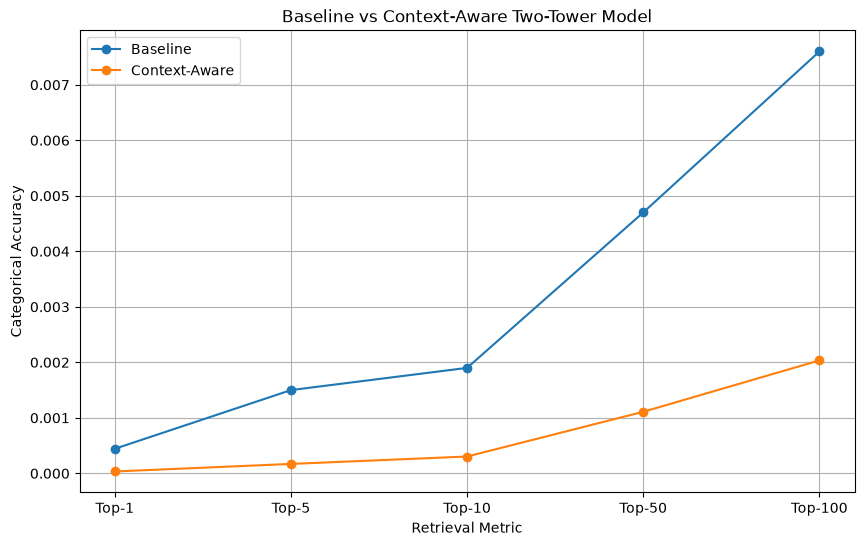

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

x = range(len(comparison_df))

plt.plot(
    x,
    comparison_df["Baseline"],
    marker="o",
    label="Baseline"
)

plt.plot(
    x,
    comparison_df["Context-Aware"],
    marker="o",
    label="Context-Aware"
)

plt.xticks(x, comparison_df["Metric"])
plt.xlabel("Retrieval Metric")
plt.ylabel("Categorical Accuracy")
plt.title("Baseline vs Context-Aware Two-Tower Model")
plt.legend()
plt.grid(True)

plt.show()

In [51]:
comparison_path = os.path.join(
    processed_path,
    "two_tower_context_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("Comparison saved to:")
print(comparison_path)

Comparison saved to:
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\data\processed\two_tower_context_comparison.csv


In [52]:
model_path = os.path.join(
    project_root,
    "models",
    "two_tower"
)

os.makedirs(model_path, exist_ok=True)

print("Model directory:")
print(model_path)

Model directory:
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\models\two_tower


In [53]:
context_user_model.save(
    os.path.join(model_path, "context_user_tower.keras")
)

context_item_model.save(
    os.path.join(model_path, "context_item_tower.keras")
)

print("Context-aware towers saved successfully.")

Context-aware towers saved successfully.


In [54]:
item_embedding_df = item_features_df[
    [
        "article_id",
        "product_type_no",
        "purchase_count",
        "avg_price",
        "total_revenue"
    ]
].copy()

item_embedding_df = item_embedding_df.rename(
    columns={
        "purchase_count": "item_purchase_count"
    }
)

item_embedding_ds = tf.data.Dataset.from_tensor_slices({
    "article_id": item_embedding_df["article_id"].astype(str).values,
    "product_type_no": item_embedding_df["product_type_no"].astype("float32").values,
    "item_purchase_count": item_embedding_df["item_purchase_count"].astype("float32").values,
    "avg_price": item_embedding_df["avg_price"].astype("float32").values,
    "total_revenue": item_embedding_df["total_revenue"].astype("float32").values
}).batch(4096)

print("Item embedding dataset created.")
print("Items:", len(item_embedding_df))

Item embedding dataset created.
Items: 105542


In [55]:
item_embeddings = context_item_model.predict(
    item_embedding_ds,
    verbose=1
)

print("Item embeddings shape:")
print(item_embeddings.shape)

26/26 [==============================] - 4s 130ms/step
Item embeddings shape:
(105542, 64)


In [56]:
item_embedding_path = os.path.join(
    model_path,
    "item_embeddings.npy"
)

item_id_path = os.path.join(
    model_path,
    "item_ids.npy"
)

np.save(item_embedding_path, item_embeddings)
np.save(
    item_id_path,
    item_embedding_df["article_id"].astype(str).values
)

print("Item embeddings saved.")
print(item_embedding_path)
print(item_id_path)

Item embeddings saved.
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\models\two_tower\item_embeddings.npy
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\models\two_tower\item_ids.npy


In [57]:
user_embedding_df = user_features_df[
    [
        "customer_id",
        "age",
        "purchase_count",
        "avg_purchase_price",
        "total_spend"
    ]
].copy()

user_embedding_df = user_embedding_df.rename(
    columns={
        "purchase_count": "user_purchase_count"
    }
)

user_embedding_ds = tf.data.Dataset.from_tensor_slices({
    "customer_id": user_embedding_df["customer_id"].astype(str).values,
    "age": user_embedding_df["age"].astype("float32").values,
    "user_purchase_count": user_embedding_df["user_purchase_count"].astype("float32").values,
    "avg_purchase_price": user_embedding_df["avg_purchase_price"].astype("float32").values,
    "total_spend": user_embedding_df["total_spend"].astype("float32").values
}).batch(4096)

print("User embedding dataset created.")
print("Users:", len(user_embedding_df))

User embedding dataset created.
Users: 1371980


In [58]:
user_embeddings = context_user_model.predict(
    user_embedding_ds,
    verbose=1
)

print("User embeddings shape:")
print(user_embeddings.shape)

335/335 [==============================] - 377s 1s/step
User embeddings shape:
(1371980, 64)


In [59]:
user_embedding_path = os.path.join(
    model_path,
    "user_embeddings.npy"
)

user_id_path = os.path.join(
    model_path,
    "user_ids.npy"
)

np.save(user_embedding_path, user_embeddings)

np.save(
    user_id_path,
    user_embedding_df["customer_id"].astype(str).values
)

print("User embeddings saved.")
print(user_embedding_path)
print(user_id_path)

User embeddings saved.
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\models\two_tower\user_embeddings.npy
C:\Users\SASHANK VARMA K\context-aware-neural-recommendation-engine\models\two_tower\user_ids.npy


In [60]:
print("Saved Two-Tower artifacts:")
print("=" * 40)

for filename in os.listdir(model_path):
    filepath = os.path.join(model_path, filename)
    
    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 ** 2)
        print(f"{filename:35s} {size_mb:8.2f} MB")

Saved Two-Tower artifacts:
context_item_tower.keras               20.40 MB
context_user_tower.keras              212.38 MB
item_embeddings.npy                    25.77 MB
item_ids.npy                            1.21 MB
user_embeddings.npy                   334.96 MB
user_ids.npy                           87.68 MB


In [61]:
from sklearn.metrics.pairwise import cosine_similarity

# Select one known user
test_user_index = 0

test_user_id = user_embedding_df.iloc[test_user_index]["customer_id"]
test_user_embedding = user_embeddings[test_user_index].reshape(1, -1)

# Compare against all item embeddings
similarities = cosine_similarity(
    test_user_embedding,
    item_embeddings
)[0]

# Get top 10 items
top_indices = np.argsort(similarities)[::-1][:10]

retrieved_items = pd.DataFrame({
    "article_id": item_embedding_df.iloc[top_indices]["article_id"].values,
    "similarity": similarities[top_indices]
})

print("Test User:")
print(test_user_id)

print("\nTop-10 Retrieved Items:")
print(retrieved_items.to_string(index=False))

Test User:
00006413d8573cd20ed7128e53b7b13819fe5cfc2d801fe7fc0f26dd8d65a85a

Top-10 Retrieved Items:
 article_id  similarity
  707704003    0.399151
  779725005    0.390536
  594978004    0.368911
  566140015    0.365167
  664405005    0.363313
  562211012    0.361760
  516859007    0.361412
  629758013    0.359373
  757903001    0.355382
  699867001    0.354937


In [62]:
print("Two-Tower Training Summary")
print("=" * 50)

print("\nBaseline Validation:")
for metric, value in baseline_metrics.items():
    print(f"{metric:8s}: {value:.6f}")

print("\nContext-Aware Validation:")
for metric, value in context_metrics.items():
    print(f"{metric:8s}: {value:.6f}")

print("\nModel Configuration:")
print("Embedding dimension: 64")
print("Training interactions:", len(train_df))
print("Validation interactions:", len(validation_df))
print("User vocabulary:", len(user_vocabulary))
print("Item vocabulary:", len(item_vocabulary))

print("\nArtifacts:")
print("User tower: context_user_tower.keras")
print("Item tower: context_item_tower.keras")
print("User embeddings: user_embeddings.npy")
print("Item embeddings: item_embeddings.npy")

print("\nNotebook status: COMPLETE")

Two-Tower Training Summary

Baseline Validation:
Top-1   : 0.000443
Top-5   : 0.001500
Top-10  : 0.001900
Top-50  : 0.004700
Top-100 : 0.007600

Context-Aware Validation:
Top-1   : 0.000033
Top-5   : 0.000170
Top-10  : 0.000303
Top-50  : 0.001109
Top-100 : 0.002035

Model Configuration:
Embedding dimension: 64
Training interactions: 2002124
Validation interactions: 300304
User vocabulary: 687245
Item vocabulary: 79407

Artifacts:
User tower: context_user_tower.keras
Item tower: context_item_tower.keras
User embeddings: user_embeddings.npy
Item embeddings: item_embeddings.npy

Notebook status: COMPLETE
